# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación

## Clasificación de tumores cerebrales en resonancia magnética: CNN desde cero frente a redes preentrenadas

**Grupo 14**

**Integrantes:**

- Adrián Marcelo Roizman
- María Agustina Garcés Correa
- Sebastián Licciardello
- Gustavo Bortolazzi


# 1. Carga del conjunto de datos

Se comprueba que el entorno dispone de GPU y se descarga el dataset *Brain Tumor MRI Dataset* desde Kaggle.

In [1]:
import tensorflow as tf

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import kagglehub

DATA_DIR = kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset')

print('Ruta del dataset:', DATA_DIR)
print('Contenido:', os.listdir(DATA_DIR))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Ruta del dataset: /kaggle/input/brain-tumor-mri-dataset
Contenido: ['Training', 'Testing']



# 2. Exploración del conjunto de datos
Se cuenta el número de imágenes por clase en entrenamiento y test, y se visualizan algunos ejemplos.

In [3]:
CLASSES = sorted(os.listdir(os.path.join(DATA_DIR, 'Training')))
print('Clases:', CLASSES)

for split in ['Training', 'Testing']:
    print(f'\n{split}:')
    total = 0
    for c in CLASSES:
        n = len(os.listdir(os.path.join(DATA_DIR, split, c)))
        total += n
        print(f'  {c:12s} {n:5d}')
    print(f'  {"TOTAL":12s} {total:5d}')


Clases: ['glioma', 'meningioma', 'notumor', 'pituitary']

Training:
  glioma        1400
  meningioma    1400
  notumor       1400
  pituitary     1400
  TOTAL         5600

Testing:
  glioma         400
  meningioma     400
  notumor        400
  pituitary      400
  TOTAL         1600


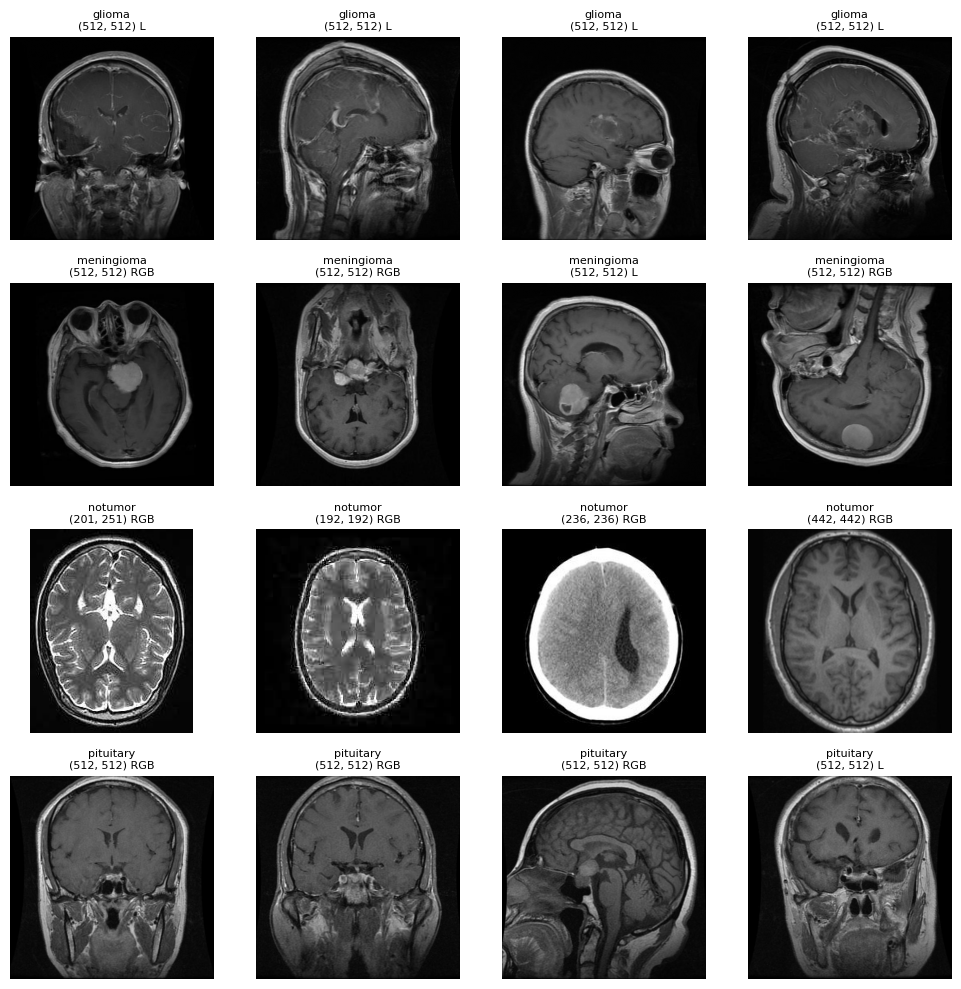

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, c in enumerate(CLASSES):
    folder = os.path.join(DATA_DIR, 'Training', c)
    for j, f in enumerate(sorted(os.listdir(folder))[:4]):
        img = Image.open(os.path.join(folder, f))
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].set_title(f'{c}\n{img.size} {img.mode}', fontsize=8)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

**Observaciones:**
- El conjunto está balanceado: 1.400 imágenes por clase en entrenamiento (5.600) y 400 por clase en test (1.600). Por ello la *accuracy* es una métrica adecuada.
- No existe partición de validación, por lo que se reservará un 20 % del entrenamiento.
- Todas las imágenes son de 512 × 512 píxeles, pero algunas están almacenadas en escala de grises (L) y otras en RGB. Se cargarán todas en RGB y se redimensionarán a 224 × 224, el tamaño de entrada de las redes preentrenadas en ImageNet.
- Aparecen cortes axiales, sagitales y coronales, lo que aporta variabilidad.

# 3. Preparación de los datos
Se cargan las imágenes con `image_dataset_from_directory`, redimensionadas a 224 × 224 y en RGB. Se reserva un 20 % del entrenamiento para validación. Se define además una capa de *data augmentation* que se aplicará solo durante el entrenamiento.

In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'Training'),
    validation_split=0.2, subset='training', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode='rgb', label_mode='categorical')

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'Training'),
    validation_split=0.2, subset='validation', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode='rgb', label_mode='categorical')

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, 'Testing'),
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode='rgb', label_mode='categorical', shuffle=False)

print('Clases:', train_ds.class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Clases: ['glioma', 'meningioma', 'notumor', 'pituitary']


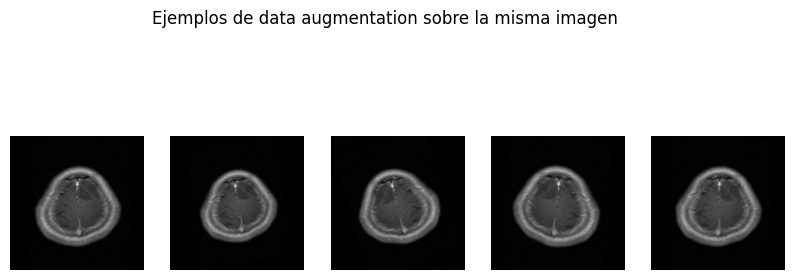

In [6]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name='data_augmentation')

images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 4))
for i in range(5):
    aug = data_augmentation(images[:1], training=True)
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug[0].numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle('Ejemplos de data augmentation sobre la misma imagen')
plt.show()

**Resumen de la preparación de los datos:**
- Se obtienen 4.480 imágenes de entrenamiento, 1.120 de validación (20 % del conjunto de entrenamiento, con semilla fija para que no se solapen) y 1.600 de test.
- Todas las imágenes se redimensionan de 512 × 512 a 224 × 224 y se cargan en RGB (3 canales), incluso las almacenadas en escala de grises, ya que es el formato de entrada que esperan las redes preentrenadas en ImageNet.
- Las etiquetas se codifican en *one-hot* (`label_mode='categorical'`), por lo que los modelos usarán una salida *softmax* de 4 neuronas y la pérdida *categorical crossentropy*.
- El conjunto de test no se baraja (`shuffle=False`) para que las predicciones conserven el orden y pueda calcularse la matriz de confusión.
- La normalización no se aplica aquí, sino dentro de cada modelo: la CNN desde cero divide entre 255 y cada red preentrenada utiliza su propia función de preprocesado, que debe coincidir con la empleada en su entrenamiento original.
- El *data augmentation* (volteo horizontal, rotación de ±18° y zoom de ±10 %) se aplica solo durante el entrenamiento. Se eligen transformaciones suaves para que las imágenes sigan siendo resonancias realistas; no se usa volteo vertical porque no representa una orientación anatómica plausible.

# 4. CNN desde cero
## 4.1 Modelo base (sin regularización)
Se entrena primero una CNN sencilla sin técnicas de regularización, que servirá como referencia para medir el efecto de la regularización.

In [7]:
from tensorflow.keras import models, regularizers, callbacks

results = {}   # aquí guardamos el resultado de cada modelo para compararlos al final

def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val')
    ax[0].set_title(f'{title} - pérdida'); ax[0].set_xlabel('época'); ax[0].legend()
    ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='val')
    ax[1].set_title(f'{title} - accuracy'); ax[1].set_xlabel('época'); ax[1].legend()
    plt.show()

def get_callbacks(patience=6):
    return [
        callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=3, min_lr=1e-6),
    ]

In [8]:
def build_cnn_base():
    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(4, activation='softmax'),
    ], name='CNN_base')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

cnn_base = build_cnn_base()
cnn_base.summary()

Model: "CNN_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,811,588 (25.98 MB)

 Trainable params: 6,811,588 (25.98 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 129ms/step - accuracy: 0.6705 - loss: 0.8020 - val_accuracy: 0.8107 - val_loss: 0.5099 - learning_rate: 0.0010
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.8299 - loss: 0.4373 - val_accuracy: 0.8607 - val_loss: 0.4021 - learning_rate: 0.0010
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8891 - loss: 0.2913 - val_accuracy: 0.9054 - val_loss: 0.2928 - learning_rate: 0.0010
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.9321 - loss: 0.1771 - val_accuracy: 0.9098 - val_loss: 0.2917 - learning_rate: 0.0010
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.9580 - loss: 0.1111 - val_accuracy: 0.9143 - val_loss: 0.3378 - learning_rate: 0.0010
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9759 - loss: 0.0637 - val_accuracy: 0.9304 - val_loss: 0.3151 - learning_rate: 0.0010
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.9868 - 

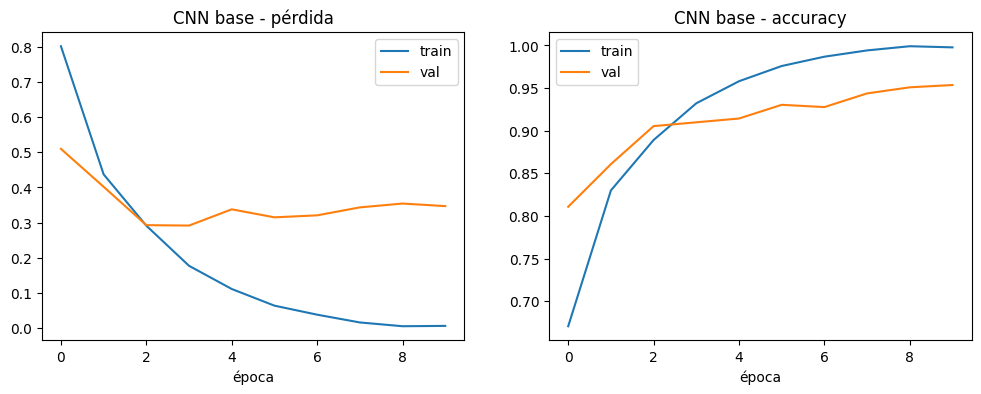

Accuracy en validación: 0.9098


In [9]:
history_base = cnn_base.fit(train_ds, validation_data=val_ds,
                            epochs=30, callbacks=get_callbacks())
plot_history(history_base, 'CNN base')

val_loss, val_acc = cnn_base.evaluate(val_ds, verbose=0)
results['CNN base'] = val_acc
print(f'Accuracy en validación: {val_acc:.4f}')

**Observaciones del modelo base:**
- El modelo alcanza un 99,8 % de *accuracy* en entrenamiento, pero la pérdida de validación alcanza su mínimo en la época 4 (≈ 0,29) y a partir de ahí aumenta: el modelo sobreajusta.
- El *EarlyStopping* detiene el entrenamiento en la época 10 y recupera los pesos de la época 4.
- El 94 % de los 6,8 millones de parámetros se concentra en la capa densa posterior al `Flatten` (50.176 × 128). Esta capa favorece la memorización y será el primer punto a modificar en el modelo regularizado.

## 4.2 Estudio de ablación: efecto de cada técnica de regularización
Para justificar experimentalmente cada decisión, se parte del modelo base y se añade una técnica cada vez, manteniendo fijo el resto (mismos datos, semilla, optimizador y *callbacks*). Esto permite atribuir a cada técnica su efecto sobre la generalización.

**A2 – GlobalAveragePooling en lugar de Flatten.** Motivación: en el modelo base el 94 % de los parámetros está en la capa densa posterior al `Flatten`. `GlobalAveragePooling2D` resume cada mapa de activación en su valor medio, de modo que reduce drásticamente los parámetros y obliga a la red a basarse en *qué* rasgos aparecen y no en *dónde* exactamente aparecen. Es una propiedad deseable en resonancias, donde el tumor puede estar en cualquier región del cerebro.

In [10]:
import time
import pandas as pd

def build_cnn(name, use_gap=False, use_aug=False, use_reg=False, l2=1e-4):
    reg = regularizers.l2(l2) if use_reg else None

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs) if use_aug else inputs
    x = layers.Rescaling(1./255)(x)

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same',
                          kernel_regularizer=reg, use_bias=not use_reg)(x)
        if use_reg:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x) if use_gap else layers.Flatten()(x)
    if use_reg:
        x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=reg)(x)
    if use_reg:
        x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(4, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def run_experiment(model, epochs=40, patience=8):
    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=get_callbacks(patience), verbose=2)
    minutes = (time.time() - t0) / 60
    plot_history(history, model.name)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    results[model.name] = {'parámetros': model.count_params(),
                           'val_accuracy': round(val_acc, 4),
                           'val_loss': round(val_loss, 4),
                           'épocas': len(history.history['loss']),
                           'minutos': round(minutes, 1)}
    print(f'{model.name}: val_accuracy = {val_acc:.4f} | val_loss = {val_loss:.4f}')
    return history


def show_results():
    display(pd.DataFrame(results).T)


# Se registra también el modelo base (A1) con el mismo formato
vl, va = cnn_base.evaluate(val_ds, verbose=0)
results = {'A1_base': {'parámetros': cnn_base.count_params(),
                       'val_accuracy': round(va, 4), 'val_loss': round(vl, 4),
                       'épocas': len(history_base.history['loss']), 'minutos': None}}
show_results()

,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN


Model: "A2_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
140/140 - 16s - 113ms/step - accuracy: 0.4783 - loss: 1.1109 - val_accuracy: 0.6438 - val_loss: 0.8819 - learning_rate: 0.0010
Epoch 2/40
140/140 - 11s - 80ms/step - accuracy: 0.6297 - loss: 0.8893 - val_accuracy: 0.7357 - val_loss: 0.7564 - learning_rate: 0.0010
Epoch 3/40
140/140 - 20s - 144ms/step - accuracy: 0.7076 - loss: 0.7320 - val_accuracy: 0.7598 - val_loss: 0.5979 - learning_rate: 0.0010
Epoch 4/40
140/140 - 10s - 75ms/step - accuracy: 0.7491 - loss: 0.6213 - val_accuracy: 0.8018 - val_loss: 0.5033 - learning_rate: 0.0010
Epoch 5/40
140/140 - 12s - 82ms/step - accuracy: 0.7632 - loss: 0.5802 - val_accuracy: 0.7875 - val_loss: 0.5058 - learning_rate: 0.0010
Epoch 6/40
140/140 - 19s - 139ms/step - accuracy: 0.7757 - loss: 0.5570 - val_accuracy: 0.8134 - val_loss: 0.4835 - learning_rate: 0.0010
Epoch 7/40
140/140 - 11s - 76ms/step - accuracy: 0.7949 - loss: 0.5119 - val_accuracy: 0.7991 - val_loss: 0.5121 - learning_rate: 0.0010
Epoch 8/40
140/140 - 11s - 82ms/step -

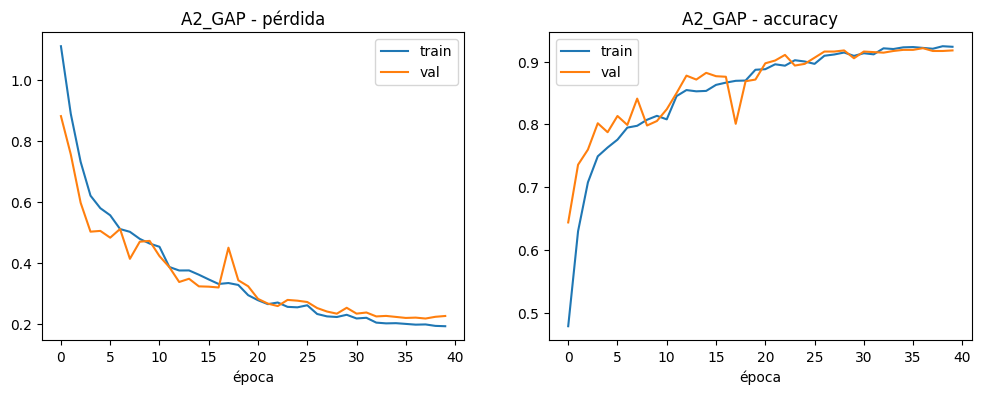

A2_GAP: val_accuracy = 0.9170 | val_loss = 0.2186


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5


In [11]:
cnn_a2 = build_cnn('A2_GAP', use_gap=True)
cnn_a2.summary()
history_a2 = run_experiment(cnn_a2)
show_results()

Se guardan en Google Drive los modelos entrenados y la tabla de resultados, para no tener que reentrenar si la sesión de Colab se desconecta. A partir de aquí, cada experimento termina con `save_progress(modelo)`.

In [12]:
from google.colab import drive
import json
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/Proyecto_Brain_Tumor'
os.makedirs(SAVE_DIR, exist_ok=True)

def save_progress(model):
    model.save(f'{SAVE_DIR}/{model.name}.keras')
    with open(f'{SAVE_DIR}/results.json', 'w') as f:
        json.dump(results, f, indent=2, default=float)
    print('Guardado:', model.name)

save_progress(cnn_base)
save_progress(cnn_a2)

**Observaciones A2 (GAP):**
- Sustituir `Flatten` por `GlobalAveragePooling2D` reduce los parámetros de 6,8 M a 0,42 M (16 veces menos).
- La *accuracy* de validación sube de 0,910 a 0,917 y la pérdida baja de 0,292 a 0,219.
- Las curvas de entrenamiento y validación evolucionan juntas: se elimina el sobreajuste.
- El modelo no se detiene antes de la época 40 y la pérdida seguía bajando, por lo que en los siguientes experimentos se amplía el número máximo de épocas.

**A3 – GAP + data augmentation.** Se añaden volteos horizontales, rotaciones y zoom aleatorios durante el entrenamiento para aumentar la variabilidad de las imágenes y mejorar la robustez frente a cambios de posición y orientación del corte.

Epoch 1/60
140/140 - 18s - 129ms/step - accuracy: 0.4725 - loss: 1.1264 - val_accuracy: 0.6304 - val_loss: 0.8963 - learning_rate: 0.0010
Epoch 2/60
140/140 - 12s - 83ms/step - accuracy: 0.6127 - loss: 0.9183 - val_accuracy: 0.5929 - val_loss: 0.8630 - learning_rate: 0.0010
Epoch 3/60
140/140 - 11s - 75ms/step - accuracy: 0.6877 - loss: 0.7630 - val_accuracy: 0.6223 - val_loss: 0.9278 - learning_rate: 0.0010
Epoch 4/60
140/140 - 10s - 73ms/step - accuracy: 0.7092 - loss: 0.7012 - val_accuracy: 0.5259 - val_loss: 1.1890 - learning_rate: 0.0010
Epoch 5/60
140/140 - 10s - 68ms/step - accuracy: 0.7297 - loss: 0.6580 - val_accuracy: 0.7295 - val_loss: 0.6460 - learning_rate: 0.0010
Epoch 6/60
140/140 - 12s - 82ms/step - accuracy: 0.7520 - loss: 0.6174 - val_accuracy: 0.6705 - val_loss: 0.8635 - learning_rate: 0.0010
Epoch 7/60
140/140 - 11s - 75ms/step - accuracy: 0.7560 - loss: 0.5885 - val_accuracy: 0.6804 - val_loss: 0.7486 - learning_rate: 0.0010
Epoch 8/60
140/140 - 11s - 79ms/step - a

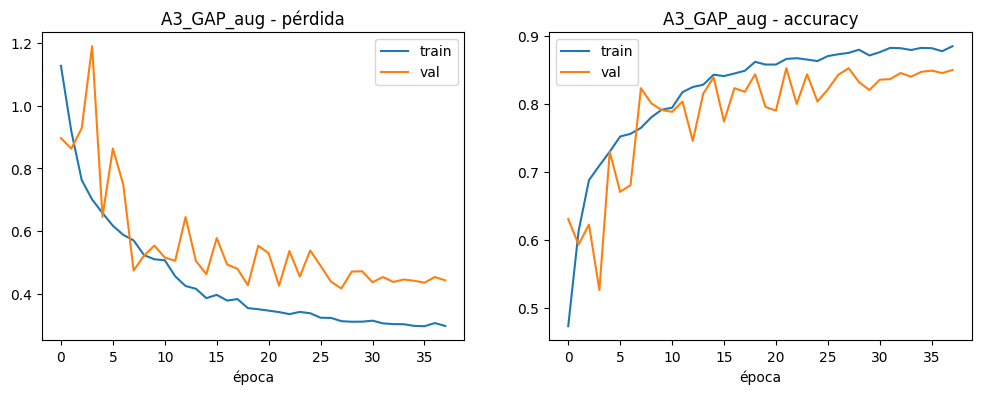

A3_GAP_aug: val_accuracy = 0.8527 | val_loss = 0.4177


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5
A3_GAP_aug,421828.0,0.8527,0.4177,38.0,7.7


Guardado: A3_GAP_aug


In [13]:
cnn_a3 = build_cnn('A3_GAP_aug', use_gap=True, use_aug=True)
history_a3 = run_experiment(cnn_a3, epochs=60, patience=10)
show_results()
save_progress(cnn_a3)

**Observaciones A3 (GAP + data augmentation):**
- Contra lo esperado, el *data augmentation* empeora el resultado: la *accuracy* de validación baja de 0,917 a 0,853 y la pérdida sube de 0,219 a 0,418.
- La *accuracy* de entrenamiento también disminuye (0,92 → 0,88), lo que indica falta de capacidad (*underfitting*) y no sobreajuste: una red pequeña sin normalización no consigue aprender la variabilidad añadida.
- La curva de validación es muy inestable, y el *callback* `ReduceLROnPlateau` reduce la tasa de aprendizaje hasta 7,8·10⁻⁶, lo que frena el aprendizaje.
- Hipótesis: la *Batch Normalization* debería estabilizar el entrenamiento y permitir aprovechar el *augmentation*. Se comprueba en A4.

**A4 – Regularización completa (BatchNormalization + Dropout + L2).** Se añade normalización por lotes tras cada convolución, *Dropout* antes y después de la capa densa y penalización L2 en los pesos. Para separar el efecto del *augmentation*, se entrenan dos variantes: con y sin *augmentation*.

Epoch 1/60
140/140 - 25s - 178ms/step - accuracy: 0.6123 - loss: 1.0113 - val_accuracy: 0.2339 - val_loss: 2.7859 - learning_rate: 0.0010
Epoch 2/60
140/140 - 20s - 144ms/step - accuracy: 0.6806 - loss: 0.8410 - val_accuracy: 0.3714 - val_loss: 2.5532 - learning_rate: 0.0010
Epoch 3/60
140/140 - 20s - 145ms/step - accuracy: 0.7167 - loss: 0.7556 - val_accuracy: 0.5143 - val_loss: 1.6037 - learning_rate: 0.0010
Epoch 4/60
140/140 - 20s - 142ms/step - accuracy: 0.7424 - loss: 0.7037 - val_accuracy: 0.7902 - val_loss: 0.6453 - learning_rate: 0.0010
Epoch 5/60
140/140 - 20s - 145ms/step - accuracy: 0.7571 - loss: 0.6721 - val_accuracy: 0.4295 - val_loss: 2.7253 - learning_rate: 0.0010
Epoch 6/60
140/140 - 21s - 149ms/step - accuracy: 0.7703 - loss: 0.6507 - val_accuracy: 0.5393 - val_loss: 2.4940 - learning_rate: 0.0010
Epoch 7/60
140/140 - 41s - 291ms/step - accuracy: 0.7799 - loss: 0.6174 - val_accuracy: 0.4750 - val_loss: 2.5269 - learning_rate: 0.0010
Epoch 8/60
140/140 - 21s - 151ms/s

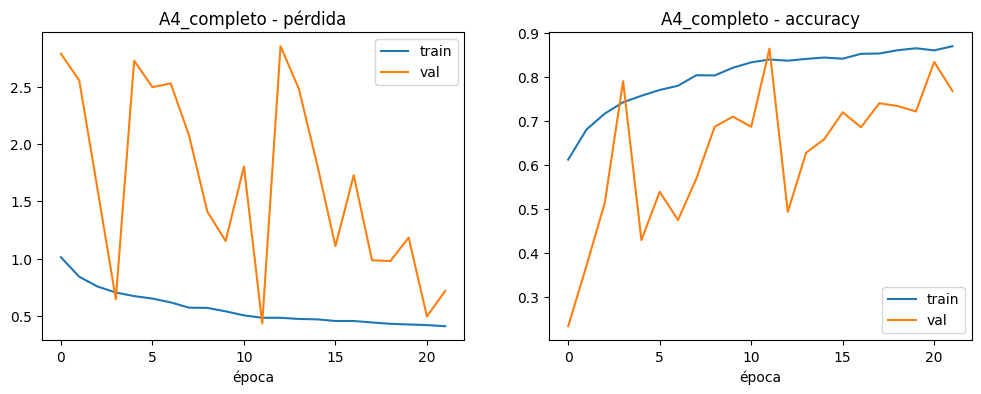

A4_completo: val_accuracy = 0.8643 | val_loss = 0.4339
Guardado: A4_completo
Epoch 1/60
140/140 - 26s - 187ms/step - accuracy: 0.6219 - loss: 0.9833 - val_accuracy: 0.3509 - val_loss: 2.2076 - learning_rate: 0.0010
Epoch 2/60
140/140 - 12s - 89ms/step - accuracy: 0.7109 - loss: 0.7725 - val_accuracy: 0.3357 - val_loss: 2.6015 - learning_rate: 0.0010
Epoch 3/60
140/140 - 22s - 154ms/step - accuracy: 0.7516 - loss: 0.6875 - val_accuracy: 0.4446 - val_loss: 2.3061 - learning_rate: 0.0010
Epoch 4/60
140/140 - 13s - 96ms/step - accuracy: 0.7701 - loss: 0.6262 - val_accuracy: 0.7170 - val_loss: 0.7482 - learning_rate: 0.0010
Epoch 5/60
140/140 - 13s - 93ms/step - accuracy: 0.7864 - loss: 0.6101 - val_accuracy: 0.7009 - val_loss: 0.9981 - learning_rate: 0.0010
Epoch 6/60
140/140 - 13s - 92ms/step - accuracy: 0.7971 - loss: 0.5730 - val_accuracy: 0.2920 - val_loss: 5.1535 - learning_rate: 0.0010
Epoch 7/60
140/140 - 12s - 86ms/step - accuracy: 0.8145 - loss: 0.5344 - val_accuracy: 0.5830 - val

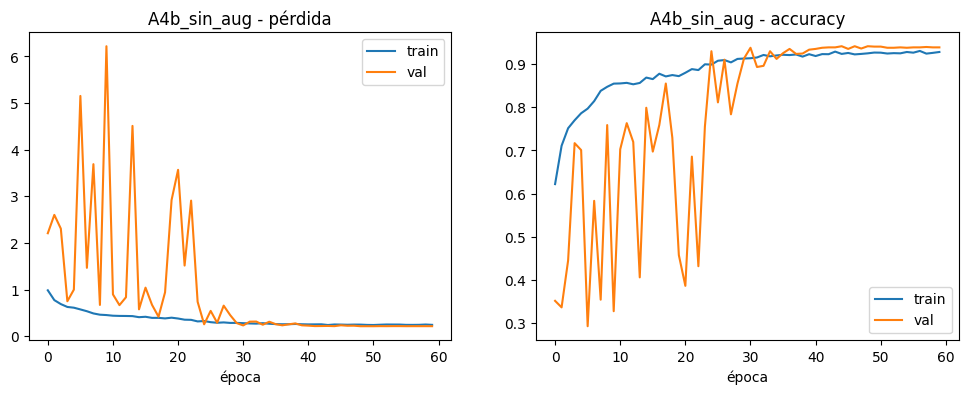

A4b_sin_aug: val_accuracy = 0.9411 | val_loss = 0.2126
Guardado: A4b_sin_aug


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5
A3_GAP_aug,421828.0,0.8527,0.4177,38.0,7.7
A4_completo,423268.0,0.8643,0.4339,22.0,10.0
A4b_sin_aug,423268.0,0.9411,0.2126,60.0,13.7


In [14]:
cnn_a4 = build_cnn('A4_completo', use_gap=True, use_aug=True, use_reg=True)
history_a4 = run_experiment(cnn_a4, epochs=60, patience=10)
save_progress(cnn_a4)

cnn_a4b = build_cnn('A4b_sin_aug', use_gap=True, use_aug=False, use_reg=True)
history_a4b = run_experiment(cnn_a4b, epochs=60, patience=10)
save_progress(cnn_a4b)

show_results()

**Observaciones A4 (regularización completa):**
- La mejor configuración es A4b (GAP + BatchNormalization + Dropout + L2, sin *augmentation*): 0,941 de *accuracy* en validación y la menor pérdida (0,213), con 16 veces menos parámetros que el modelo base.
- Durante las primeras ~25 épocas la validación es muy inestable. Es un efecto conocido de la *Batch Normalization*: en entrenamiento normaliza con las estadísticas de cada *batch*, pero en validación usa medias móviles que aún no se han estabilizado. Cuando `ReduceLROnPlateau` reduce la tasa de aprendizaje, la validación converge con el entrenamiento.
- A4 (con *augmentation*) se detuvo en la época 22, todavía en la fase inestable. Para descartar que el resultado se deba a una parada prematura, se repite con mayor paciencia (A4c).

Epoch 1/80
140/140 - 23s - 163ms/step - accuracy: 0.6136 - loss: 0.9961 - val_accuracy: 0.2545 - val_loss: 2.6773 - learning_rate: 0.0010
Epoch 2/80
140/140 - 19s - 137ms/step - accuracy: 0.6886 - loss: 0.8249 - val_accuracy: 0.3304 - val_loss: 2.0861 - learning_rate: 0.0010
Epoch 3/80
140/140 - 23s - 165ms/step - accuracy: 0.7089 - loss: 0.7784 - val_accuracy: 0.4777 - val_loss: 1.8366 - learning_rate: 0.0010
Epoch 4/80
140/140 - 39s - 276ms/step - accuracy: 0.7319 - loss: 0.7158 - val_accuracy: 0.6768 - val_loss: 0.8431 - learning_rate: 0.0010
Epoch 5/80
140/140 - 41s - 293ms/step - accuracy: 0.7578 - loss: 0.6840 - val_accuracy: 0.3786 - val_loss: 3.4099 - learning_rate: 0.0010
Epoch 6/80
140/140 - 20s - 146ms/step - accuracy: 0.7732 - loss: 0.6570 - val_accuracy: 0.4866 - val_loss: 2.1883 - learning_rate: 0.0010
Epoch 7/80
140/140 - 22s - 154ms/step - accuracy: 0.7924 - loss: 0.5987 - val_accuracy: 0.7911 - val_loss: 0.6383 - learning_rate: 0.0010
Epoch 8/80
140/140 - 20s - 144ms/s

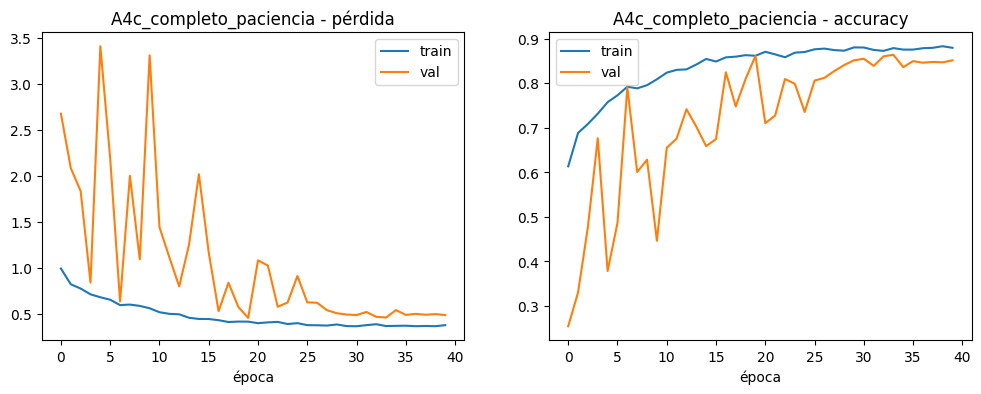

A4c_completo_paciencia: val_accuracy = 0.8616 | val_loss = 0.4594
Guardado: A4c_completo_paciencia


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5
A3_GAP_aug,421828.0,0.8527,0.4177,38.0,7.7
A4_completo,423268.0,0.8643,0.4339,22.0,10.0
A4b_sin_aug,423268.0,0.9411,0.2126,60.0,13.7
A4c_completo_paciencia,423268.0,0.8616,0.4594,40.0,16.7


In [15]:
cnn_a4c = build_cnn('A4c_completo_paciencia', use_gap=True, use_aug=True, use_reg=True)
history_a4c = run_experiment(cnn_a4c, epochs=80, patience=20)
save_progress(cnn_a4c)
show_results()

**Observaciones A4c:** con el doble de paciencia, el modelo con *augmentation* alcanza 0,862 de *accuracy* en validación, prácticamente igual que A4 (0,864). Se descarta que el mal resultado se deba a una parada prematura: en este conjunto de datos el *augmentation* empeora el rendimiento.

## 4.3 Conclusiones del estudio de ablación

| Experimento | Cambio | val_accuracy | Parámetros |
|---|---|---|---|
| A1 | Base (Flatten) | 0,910 | 6,8 M |
| A2 | + GlobalAveragePooling | 0,917 | 0,42 M |
| A3 | + *augmentation* | 0,853 | 0,42 M |
| A4 / A4c | + BN, Dropout, L2 (con *augmentation*) | 0,864 / 0,862 | 0,42 M |
| **A4b** | **GAP + BN, Dropout, L2 (sin *augmentation*)** | **0,941** | **0,42 M** |

- **GlobalAveragePooling** elimina el sobreajuste y reduce los parámetros 16 veces.
- **BatchNormalization, Dropout y L2** aportan la mayor mejora (de 0,917 a 0,941), aunque la *Batch Normalization* produce una fase inicial inestable en validación.
- El ***data augmentation* empeora** el rendimiento en todas las configuraciones probadas. Una posible explicación es que las imágenes del conjunto ya están estandarizadas (512 × 512, centradas y con fondo negro), de modo que las rotaciones y el zoom introducen una variabilidad que no existe en el test y dificultan el aprendizaje de una red pequeña.
- **Modelo seleccionado como CNN desde cero: A4b** (94,1 % en validación). Siguiendo este resultado, las redes preentrenadas se entrenarán sin *augmentation*.

# 5. Redes preentrenadas en ImageNet
## 5.1 Transfer learning (base congelada)
Se evalúan tres arquitecturas: **DenseNet121** (base de CheXNet, referente en imagen médica), **EfficientNetB0** (arquitectura moderna y eficiente) y **VGG16** (referencia clásica). En cada caso se elimina la cabeza original de 1.000 clases, se congela la base convolucional y se añade una cabeza nueva (GlobalAveragePooling + Dropout + Dense de 4 neuronas con *softmax*). Cada red recibe las imágenes con su propia función de preprocesado, que debe coincidir con la usada en su entrenamiento original. De acuerdo con el estudio de ablación, no se aplica *augmentation*.

In [16]:
from tensorflow.keras import applications as app

PRETRAINED = {
    'DenseNet121':    (app.DenseNet121,    app.densenet.preprocess_input),
    'EfficientNetB0': (app.EfficientNetB0, app.efficientnet.preprocess_input),
    'VGG16':          (app.VGG16,          app.vgg16.preprocess_input),
}

def make_datasets(preprocess):
    f = lambda x, y: (preprocess(x), y)
    return (train_ds.map(f, num_parallel_calls=AUTOTUNE),
            val_ds.map(f, num_parallel_calls=AUTOTUNE),
            test_ds.map(f, num_parallel_calls=AUTOTUNE))

def build_pretrained(arch):
    constructor, _ = PRETRAINED[arch]
    base = constructor(include_top=False, weights='imagenet',
                       input_shape=IMG_SIZE + (3,))
    base.trainable = False                      # base congelada

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = base(inputs, training=False)            # BN de la base en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(4, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=f'TL_{arch}')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model, base

def run_experiment(model, epochs=40, patience=8, tr=None, va=None):
    tr = train_ds if tr is None else tr
    va = val_ds if va is None else va
    t0 = time.time()
    history = model.fit(tr, validation_data=va, epochs=epochs,
                        callbacks=get_callbacks(patience), verbose=2)
    minutes = (time.time() - t0) / 60
    plot_history(history, model.name)
    val_loss, val_acc = model.evaluate(va, verbose=0)
    results[model.name] = {'parámetros': model.count_params(),
                           'val_accuracy': round(val_acc, 4),
                           'val_loss': round(val_loss, 4),
                           'épocas': len(history.history['loss']),
                           'minutos': round(minutes, 1)}
    print(f'{model.name}: val_accuracy = {val_acc:.4f} | val_loss = {val_loss:.4f}')
    return history


========== DenseNet121 ==========
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/20
140/140 - 123s - 876ms/step - accuracy: 0.6288 - loss: 0.9154 - val_accuracy: 0.8589 - val_loss: 0.4475 - learning_rate: 0.0010
Epoch 2/20
140/140 - 21s - 152ms/step - accuracy: 0.8058 - loss: 0.5306 - val_accuracy: 0.8911 - val_loss: 0.3462 - learning_rate: 0.0010
Epoch 3/20
140/140 - 20s - 142ms/step - accuracy: 0.8308 - loss: 0.4504 - val_accuracy: 0.8884 - val_loss: 0.3289 - learning_rate: 0.0010
Epoch 4/20
140/140 - 20s - 145ms/step - accuracy: 0.8391 - loss: 0.4209 - val_accuracy: 0.9107 - val_loss: 0.2968 - learning_rate: 0.0010
Epoch 5/20
140/140 - 20s - 146ms/step - accuracy: 0.8551 - loss: 0.3853 - val_accuracy: 0.9134 - val_loss: 0.2825 - learning_rate: 0.0010
Epoch 6/20
140/140 - 19s - 133ms/step - accuracy: 0.8621 - loss: 0.3728 - val_accuracy: 0.9027 - val_loss: 0.2850 - learning_rate: 0.0010
Epoch 7/20
140/140 - 19s - 137ms/step - accuracy: 0.8658 - loss: 0.3599 - val_accurac

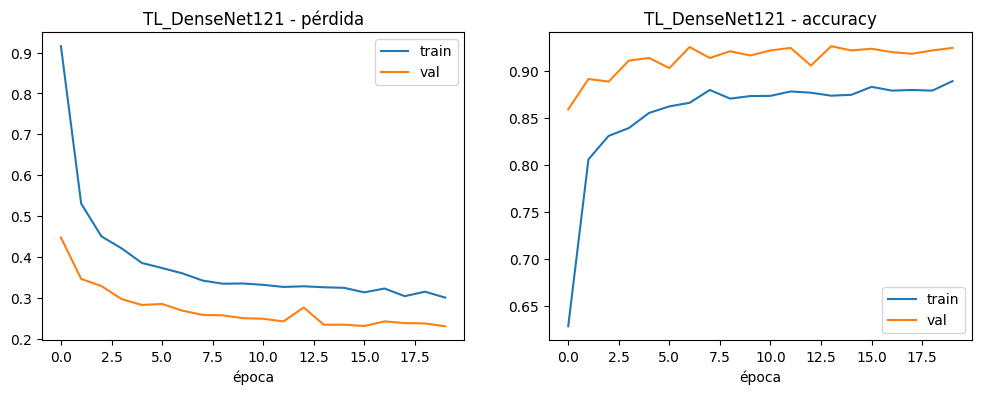

TL_DenseNet121: val_accuracy = 0.9241 | val_loss = 0.2305
Guardado: TL_DenseNet121

========== EfficientNetB0 ==========
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
140/140 - 68s - 484ms/step - accuracy: 0.7321 - loss: 0.7169 - val_accuracy: 0.8732 - val_loss: 0.4073 - learning_rate: 0.0010
Epoch 2/20
140/140 - 12s - 88ms/step - accuracy: 0.8471 - loss: 0.4401 - val_accuracy: 0.8920 - val_loss: 0.3279 - learning_rate: 0.0010
Epoch 3/20
140/140 - 13s - 91ms/step - accuracy: 0.8592 - loss: 0.3910 - val_accuracy: 0.9036 - val_loss: 0.2929 - learning_rate: 0.0010
Epoch 4/20
140/140 - 20s - 141ms/step - accuracy: 0.8777 - loss: 0.3457 - val_accuracy: 0.9116 - val_loss: 0.2712 - learning_rate: 0.0010
Epoch 5/20
140/140 - 13s - 90ms/step - accuracy: 0.8792 - loss: 0.3314 - val_accuracy: 0.9143 - val_loss: 0.2561 - learning_rate: 0.0010
Epoch 6/20
140/140 - 13s - 90ms/step - accuracy: 0.8884 - loss: 0.3110 - val_accuracy: 0.9187 - val_loss: 0.2386 - learning_rate: 0.0010
Epoc

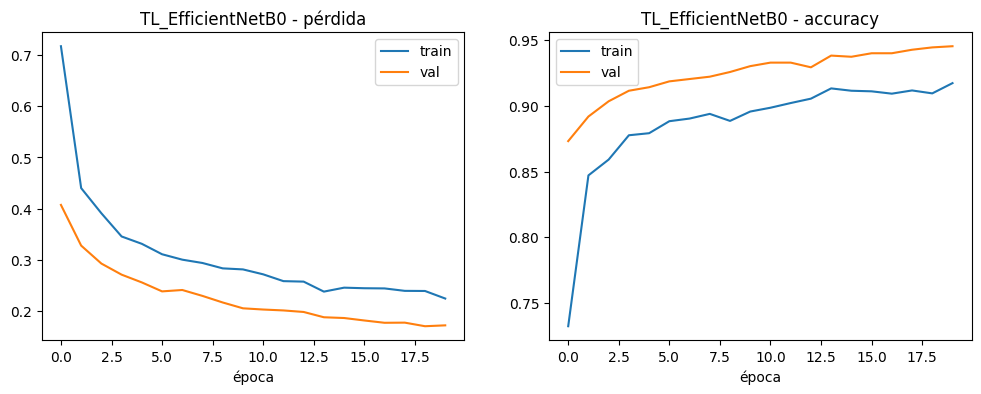

TL_EfficientNetB0: val_accuracy = 0.9446 | val_loss = 0.1706
Guardado: TL_EfficientNetB0

========== VGG16 ==========
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/20
140/140 - 48s - 341ms/step - accuracy: 0.5471 - loss: 1.9614 - val_accuracy: 0.8009 - val_loss: 0.5904 - learning_rate: 0.0010
Epoch 2/20
140/140 - 25s - 179ms/step - accuracy: 0.7310 - loss: 0.9298 - val_accuracy: 0.8518 - val_loss: 0.4398 - learning_rate: 0.0010
Epoch 3/20
140/140 - 25s - 178ms/step - accuracy: 0.7897 - loss: 0.6594 - val_accuracy: 0.8643 - val_loss: 0.3710 - learning_rate: 0.0010
Epoch 4/20
140/140 - 25s - 180ms/step - accuracy: 0.8299 - loss: 0.5059 - val_accuracy: 0.9045 - val_loss: 0.2755 - learning_rate: 0.0010
Epoch 5/20
140/140 - 25s - 180ms/step - accuracy: 0.8342 - loss: 0.4684 - val_accuracy: 0.8920 - val_loss: 0.2847 - learning_rate: 0.0010
Epoch 6/20
140/140 - 25s - 179ms/step - accuracy: 0.8574 - loss: 0.4094 - val_accuracy: 0.8705 - val_loss: 0.3128 - learning_rate: 0.0010
Epo

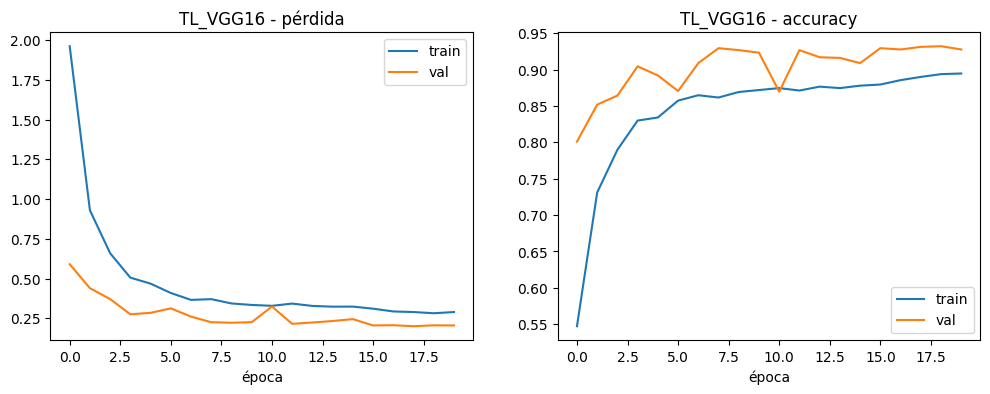

TL_VGG16: val_accuracy = 0.9312 | val_loss = 0.2005
Guardado: TL_VGG16


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5
A3_GAP_aug,421828.0,0.8527,0.4177,38.0,7.7
A4_completo,423268.0,0.8643,0.4339,22.0,10.0
A4b_sin_aug,423268.0,0.9411,0.2126,60.0,13.7
A4c_completo_paciencia,423268.0,0.8616,0.4594,40.0,16.7
TL_DenseNet121,7041604.0,0.9241,0.2305,20.0,8.1
TL_EfficientNetB0,4054695.0,0.9446,0.1706,20.0,5.7
TL_VGG16,14716740.0,0.9312,0.2005,20.0,9.1


In [17]:
tl_models, bases, datasets = {}, {}, {}

for arch in PRETRAINED:
    print(f'\n========== {arch} ==========')
    datasets[arch] = make_datasets(PRETRAINED[arch][1])
    tr, va, _ = datasets[arch]
    model, base = build_pretrained(arch)
    run_experiment(model, epochs=20, patience=5, tr=tr, va=va)
    tl_models[arch], bases[arch] = model, base
    save_progress(model)

show_results()

**Observaciones 5.1 (transfer learning):**
- EfficientNetB0 obtiene el mejor resultado (0,945 en validación, pérdida 0,171) y es además la más rápida (5,7 min). Le siguen VGG16 (0,931) y DenseNet121 (0,924).
- Con la base congelada, las redes preentrenadas apenas igualan a la mejor CNN desde cero (A4b, 0,941). Las características aprendidas en ImageNet (fotografías de objetos cotidianos) son útiles a bajo nivel (bordes, texturas), pero las de alto nivel no están adaptadas a resonancias magnéticas. Esto motiva el *fine-tuning*.
- En las tres redes la *accuracy* de validación supera a la de entrenamiento. Se debe al *Dropout*, que solo está activo durante el entrenamiento, y a que la métrica de entrenamiento se promedia a lo largo de cada época mientras el modelo aún aprende.
- Ninguna red activa el *EarlyStopping* antes de la época 20.

## 5.2 Fine-tuning
Partiendo de los modelos del apartado 5.1, se descongela el último bloque convolucional de cada red (DenseNet121: bloque `conv5`; EfficientNetB0: bloques 6 y 7; VGG16: bloque 5) y se reentrena con una tasa de aprendizaje de 1·10⁻⁵, 100 veces menor, para adaptar las características de alto nivel a las resonancias sin destruir lo aprendido en ImageNet. Las capas de *Batch Normalization* se mantienen congeladas, ya que reestimar sus estadísticas con *batches* pequeños desestabiliza el entrenamiento, como se observó en el experimento A4b.

*Nota: por el límite de uso de GPU de Colab, el fine-tuning se ejecutó en una sesión nueva. La celda siguiente vuelve a cargar los datos (con la misma semilla, por lo que la partición es idéntica), las funciones auxiliares y los modelos del apartado 5.1 guardados en Google Drive.*

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Mounted at /content/drive

========== Fine-tuning DenseNet121 ==========
Parámetros entrenables: 2,134,020 de 7,041,604
Epoch 1/20
140/140 - 119s - 847ms/step - accuracy: 0.8906 - loss: 0.2863 - val_accuracy: 0.9312 - val_loss: 0.2059 - learning_rate: 1.0000e-05
Epoch 2/20
140/140 - 16s - 115ms/step - accuracy: 0.9071 - loss: 0.2496 - val_accuracy: 0.9348 - val_loss: 0.1943 - learning_rate: 1.0000e-05
Epoch 3/20
140/140 - 18s - 131ms/step - accuracy: 0.9183 - loss: 0.2217 - val_accuracy: 0.9438 - val_loss: 0.1800 - learning_rate: 1.0000e-05
Epoch 4/20
140/140 - 18s - 127ms/step - accuracy: 0.9234 - loss: 0.1990 - val_accuracy: 0.9473 - val_loss: 0.1718 - 

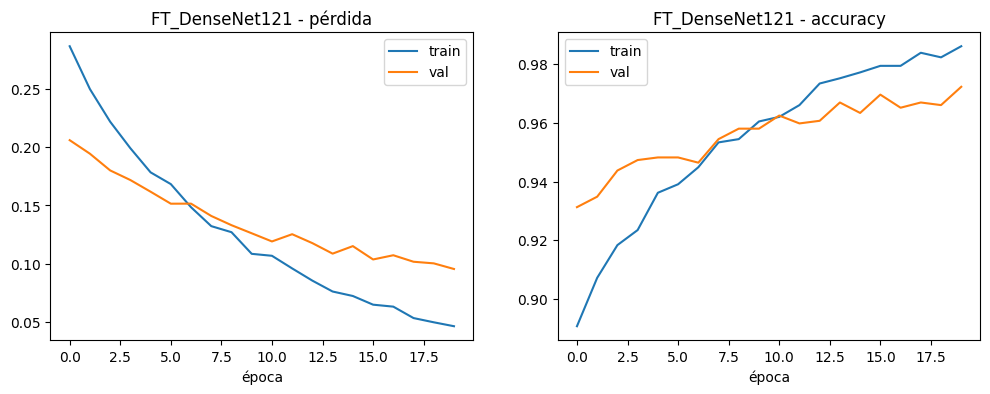

FT_DenseNet121: val_accuracy = 0.9723 | val_loss = 0.0957
Guardado: FT_DenseNet121

========== Fine-tuning EfficientNetB0 ==========
Parámetros entrenables: 3,135,008 de 4,054,695
Epoch 1/20
140/140 - 82s - 587ms/step - accuracy: 0.9107 - loss: 0.2298 - val_accuracy: 0.9482 - val_loss: 0.1577 - learning_rate: 1.0000e-05
Epoch 2/20
140/140 - 10s - 73ms/step - accuracy: 0.9257 - loss: 0.1945 - val_accuracy: 0.9518 - val_loss: 0.1424 - learning_rate: 1.0000e-05
Epoch 3/20
140/140 - 10s - 73ms/step - accuracy: 0.9353 - loss: 0.1809 - val_accuracy: 0.9509 - val_loss: 0.1384 - learning_rate: 1.0000e-05
Epoch 4/20
140/140 - 9s - 63ms/step - accuracy: 0.9366 - loss: 0.1688 - val_accuracy: 0.9598 - val_loss: 0.1225 - learning_rate: 1.0000e-05
Epoch 5/20
140/140 - 10s - 71ms/step - accuracy: 0.9444 - loss: 0.1487 - val_accuracy: 0.9536 - val_loss: 0.1245 - learning_rate: 1.0000e-05
Epoch 6/20
140/140 - 10s - 72ms/step - accuracy: 0.9475 - loss: 0.1442 - val_accuracy: 0.9616 - val_loss: 0.1108 - 

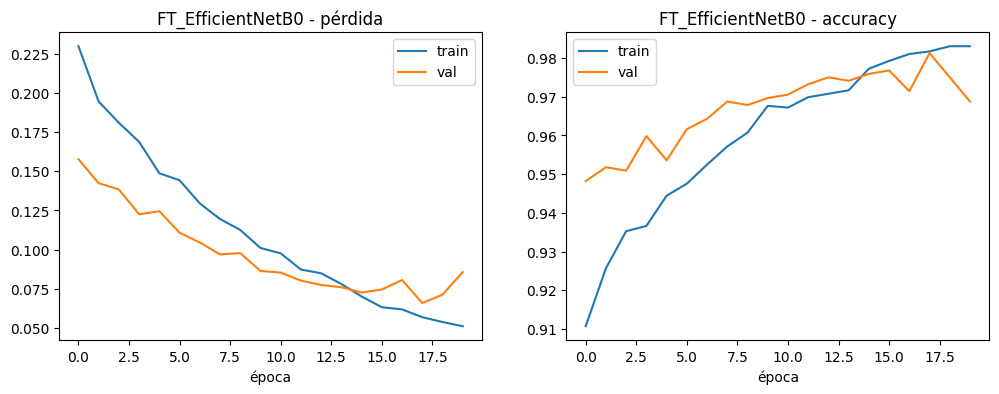

FT_EfficientNetB0: val_accuracy = 0.9812 | val_loss = 0.0659
Guardado: FT_EfficientNetB0

========== Fine-tuning VGG16 ==========
Parámetros entrenables: 7,081,476 de 14,716,740
Epoch 1/20
140/140 - 56s - 403ms/step - accuracy: 0.9089 - loss: 0.2532 - val_accuracy: 0.9446 - val_loss: 0.1640 - learning_rate: 1.0000e-05
Epoch 2/20
140/140 - 29s - 210ms/step - accuracy: 0.9462 - loss: 0.1503 - val_accuracy: 0.9563 - val_loss: 0.1339 - learning_rate: 1.0000e-05
Epoch 3/20
140/140 - 30s - 214ms/step - accuracy: 0.9663 - loss: 0.0896 - val_accuracy: 0.9688 - val_loss: 0.1101 - learning_rate: 1.0000e-05
Epoch 4/20
140/140 - 30s - 214ms/step - accuracy: 0.9790 - loss: 0.0675 - val_accuracy: 0.9688 - val_loss: 0.1035 - learning_rate: 1.0000e-05
Epoch 5/20
140/140 - 30s - 214ms/step - accuracy: 0.9833 - loss: 0.0524 - val_accuracy: 0.9688 - val_loss: 0.1038 - learning_rate: 1.0000e-05
Epoch 6/20
140/140 - 30s - 213ms/step - accuracy: 0.9879 - loss: 0.0375 - val_accuracy: 0.9732 - val_loss: 0.087

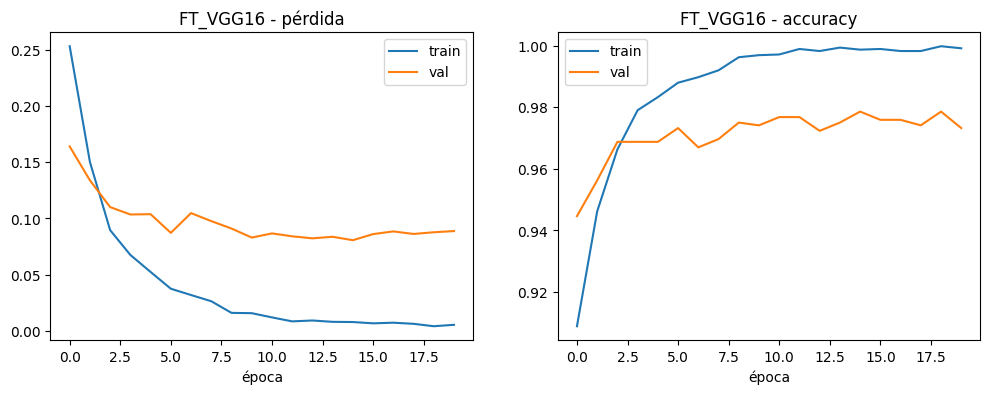

FT_VGG16: val_accuracy = 0.9786 | val_loss = 0.0806
Guardado: FT_VGG16


,parámetros,val_accuracy,val_loss,épocas,minutos
A1_base,6811588.0,0.9098,0.2917,10.0,NaN
A2_GAP,421828.0,0.9170,0.2186,40.0,9.5
A3_GAP_aug,421828.0,0.8527,0.4177,38.0,7.7
A4_completo,423268.0,0.8643,0.4339,22.0,10.0
A4b_sin_aug,423268.0,0.9411,0.2126,60.0,13.7
A4c_completo_paciencia,423268.0,0.8616,0.4594,40.0,16.7
TL_DenseNet121,7041604.0,0.9241,0.2305,20.0,8.1
TL_EfficientNetB0,4054695.0,0.9446,0.1706,20.0,5.7
TL_VGG16,14716740.0,0.9312,0.2005,20.0,9.1
FT_DenseNet121,7041604.0,0.9723,0.0957,20.0,7.6


In [18]:
# Fine-tuning en una sesión nueva: se recargan datos, funciones y modelos TL desde Drive
import os, time, json
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras import applications as app
from google.colab import drive

print('GPU:', tf.config.list_physical_devices('GPU'))

# 1. Datos (mismo split que antes: semilla 42)
DATA_DIR = kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset')
IMG_SIZE, BATCH_SIZE, SEED = (224, 224), 32, 42
AUTOTUNE = tf.data.AUTOTUNE

def load(split, subset=None, shuffle=True):
    kw = dict(validation_split=0.2, subset=subset, seed=SEED) if subset else {}
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        color_mode='rgb', label_mode='categorical', shuffle=shuffle, **kw).prefetch(AUTOTUNE)

train_ds = load('Training', 'training')
val_ds   = load('Training', 'validation')
test_ds  = load('Testing', shuffle=False)

# 2. Drive y resultados guardados
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/Proyecto_Brain_Tumor'
with open(f'{SAVE_DIR}/results.json') as f:
    results = json.load(f)

# 3. Funciones auxiliares
def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val')
    ax[0].set_title(f'{title} - pérdida'); ax[0].set_xlabel('época'); ax[0].legend()
    ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='val')
    ax[1].set_title(f'{title} - accuracy'); ax[1].set_xlabel('época'); ax[1].legend()
    plt.show()

def get_callbacks(patience=6):
    return [callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                    restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                        patience=3, min_lr=1e-6)]

def show_results():
    display(pd.DataFrame(results).T)

def save_progress(model):
    model.save(f'{SAVE_DIR}/{model.name}.keras')
    with open(f'{SAVE_DIR}/results.json', 'w') as f:
        json.dump(results, f, indent=2, default=float)
    print('Guardado:', model.name)

PRETRAINED = {
    'DenseNet121':    (app.DenseNet121,    app.densenet.preprocess_input),
    'EfficientNetB0': (app.EfficientNetB0, app.efficientnet.preprocess_input),
    'VGG16':          (app.VGG16,          app.vgg16.preprocess_input),
}

def make_datasets(preprocess):
    f = lambda x, y: (preprocess(x), y)
    return (train_ds.map(f, num_parallel_calls=AUTOTUNE),
            val_ds.map(f, num_parallel_calls=AUTOTUNE),
            test_ds.map(f, num_parallel_calls=AUTOTUNE))

def run_experiment(model, epochs=40, patience=8, tr=None, va=None):
    t0 = time.time()
    history = model.fit(tr, validation_data=va, epochs=epochs,
                        callbacks=get_callbacks(patience), verbose=2)
    minutes = (time.time() - t0) / 60
    plot_history(history, model.name)
    val_loss, val_acc = model.evaluate(va, verbose=0)
    results[model.name] = {'parámetros': model.count_params(),
                           'val_accuracy': round(val_acc, 4),
                           'val_loss': round(val_loss, 4),
                           'épocas': len(history.history['loss']),
                           'minutos': round(minutes, 1)}
    print(f'{model.name}: val_accuracy = {val_acc:.4f} | val_loss = {val_loss:.4f}')
    return history

# 4. Fine-tuning (parte de los modelos TL guardados en Drive)
FT_FROM = {'DenseNet121':    'conv5_block1_0_bn',
           'EfficientNetB0': 'block6a_expand_conv',
           'VGG16':          'block5_conv1'}

def unfreeze_from(base, first_layer):
    base.trainable = True
    unfreeze = False
    for layer in base.layers:
        if layer.name == first_layer:
            unfreeze = True
        layer.trainable = unfreeze and not isinstance(layer, layers.BatchNormalization)

for arch in PRETRAINED:
    print(f'\n========== Fine-tuning {arch} ==========')
    tl = tf.keras.models.load_model(f'{SAVE_DIR}/TL_{arch}.keras')
    base = tl.layers[1]
    tr, va, _ = make_datasets(PRETRAINED[arch][1])

    unfreeze_from(base, FT_FROM[arch])
    ft = models.Model(tl.inputs, tl.outputs, name=f'FT_{arch}')
    ft.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
               loss='categorical_crossentropy', metrics=['accuracy'])
    n_train = sum(tf.size(w).numpy() for w in ft.trainable_weights)
    print(f'Parámetros entrenables: {n_train:,} de {ft.count_params():,}')

    run_experiment(ft, epochs=20, patience=6, tr=tr, va=va)
    save_progress(ft)

show_results()

**Observaciones 5.2 (fine-tuning):**
- El *fine-tuning* produce la mayor mejora de todo el estudio: EfficientNetB0 pasa de 0,945 a 0,981 de *accuracy* en validación (pérdida de 0,171 a 0,066) y DenseNet121 de 0,924 a 0,972. Adaptar las capas de alto nivel a las resonancias magnéticas es más determinante que la arquitectura elegida.
- VGG16 también mejora, pero sobreajusta claramente: alcanza un 99,9 % en entrenamiento con una pérdida de validación estancada en torno a 0,08–0,09. Es coherente con su tamaño (14,7 M de parámetros, la mayor de las tres).
- EfficientNetB0 ofrece el mejor equilibrio entre rendimiento, tamaño (4 M de parámetros) y tiempo de entrenamiento (4,5 min). **Se selecciona como modelo final según la validación.**

# 6. Evaluación final en el conjunto de test
## 6.1 Comparación de modelos y métricas clínicas
Se evalúan sobre el conjunto de test (1.600 imágenes nunca vistas) la mejor CNN desde cero (A4b), el mejor modelo de *transfer learning* (TL_EfficientNetB0) y los tres modelos con *fine-tuning*. Además de la *accuracy*, se calculan métricas orientadas al uso clínico, agrupando las tres clases tumorales frente a «sin tumor»: **sensibilidad** (proporción de pacientes con tumor detectados), **especificidad** (proporción de pacientes sin tumor correctamente identificados) y el número de **falsos negativos** (tumores clasificados como «sin tumor»), el error más grave en un contexto de cribado.

In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
NO_TUMOR = CLASSES.index('notumor')
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])

EVAL = {'A4b_sin_aug': None,                  # CNN desde cero (normaliza dentro del modelo)
        'TL_EfficientNetB0': 'EfficientNetB0',
        'FT_DenseNet121': 'DenseNet121',
        'FT_EfficientNetB0': 'EfficientNetB0',
        'FT_VGG16': 'VGG16'}

probs, test_results = {}, {}
for name, arch in EVAL.items():
    model = tf.keras.models.load_model(f'{SAVE_DIR}/{name}.keras')
    ds = test_ds if arch is None else make_datasets(PRETRAINED[arch][1])[2]
    p = model.predict(ds, verbose=0)
    probs[name] = p
    y_pred = p.argmax(axis=1)

    tumor_true = y_true != NO_TUMOR
    tumor_pred = y_pred != NO_TUMOR
    test_results[name] = {
        'test_accuracy':      round(float((y_pred == y_true).mean()), 4),
        'sensibilidad_tumor': round(float((tumor_true & tumor_pred).sum() / tumor_true.sum()), 4),
        'especificidad':      round(float((~tumor_true & ~tumor_pred).sum() / (~tumor_true).sum()), 4),
        'falsos_negativos':   int((tumor_true & ~tumor_pred).sum()),
        'falsos_positivos':   int((~tumor_true & tumor_pred).sum()),
    }

display(pd.DataFrame(test_results).T)

,test_accuracy,sensibilidad_tumor,especificidad,falsos_negativos,falsos_positivos
A4b_sin_aug,0.8744,0.9192,1.0000,97.0,0.0
TL_EfficientNetB0,0.8806,0.9625,0.9925,45.0,3.0
FT_DenseNet121,0.9250,0.9708,1.0000,35.0,0.0
FT_EfficientNetB0,0.9319,0.9725,1.0000,33.0,0.0
FT_VGG16,0.9337,0.9725,1.0000,33.0,0.0


              precision    recall  f1-score   support

      glioma     0.9635    0.7925    0.8697       400
  meningioma     0.8653    0.9475    0.9045       400
     notumor     0.9238    1.0000    0.9604       400
   pituitary     0.9875    0.9875    0.9875       400

    accuracy                         0.9319      1600
   macro avg     0.9350    0.9319    0.9305      1600
weighted avg     0.9350    0.9319    0.9305      1600



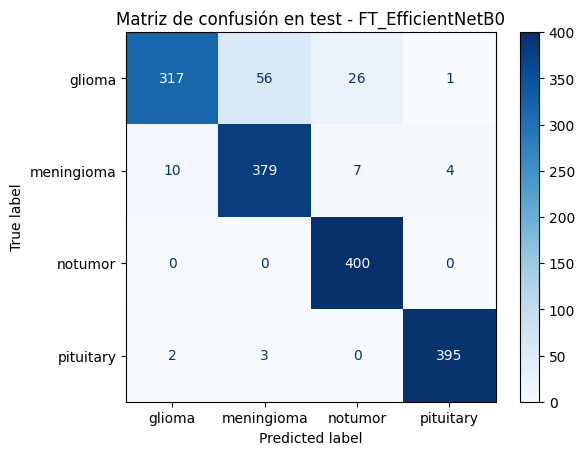

In [20]:
BEST = 'FT_EfficientNetB0'   # elegido por validación, no por test
y_pred = probs[BEST].argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=CLASSES).plot(cmap='Blues', values_format='d')
plt.title(f'Matriz de confusión en test - {BEST}')
plt.show()

**Observaciones 6.1:**
- Todos los modelos pierden entre 5 y 7 puntos de *accuracy* de validación a test (FT_EfficientNetB0: 0,981 → 0,932). Al ser una caída común a todas las arquitecturas, se atribuye a un desplazamiento de distribución entre las carpetas *Training* y *Testing* (probablemente imágenes de distinta procedencia), y no al sobreajuste de un modelo concreto. La validación, extraída del mismo origen que el entrenamiento, resulta optimista: es la situación esperable al desplegar un modelo en un hospital distinto.
- El *fine-tuning* es claramente superior: los falsos negativos bajan de 97 (CNN desde cero) y 45 (*transfer learning*) a 33.
- La clase más difícil es el glioma (*recall* 0,79): 56 se confunden con meningioma y 26 con «sin tumor». Pituitaria (0,99) y «sin tumor» (1,00) se reconocen casi perfectamente.
- Desde el punto de vista clínico, el modelo es asimétrico en el sentido no deseado: tiene especificidad 1,00 (ningún falso positivo) pero 33 falsos negativos (26 gliomas y 7 meningiomas diagnosticados como «sin tumor»). Esto motiva el ajuste de un umbral de decisión orientado a la seguridad del paciente.

## 6.2 Umbral de seguridad clínica
En cribado es preferible un falso positivo (un paciente sano derivado a más pruebas) que un falso negativo (un tumor no detectado). Se modifica la regla de decisión: el modelo solo predice «sin tumor» si su probabilidad supera un umbral *t*; en caso contrario, se asigna la clase tumoral más probable. El umbral se elige **en validación**, como el valor más exigente que mantiene una especificidad ≥ 95 %, y después se evalúa en test.

Umbral elegido en validación: 0.98


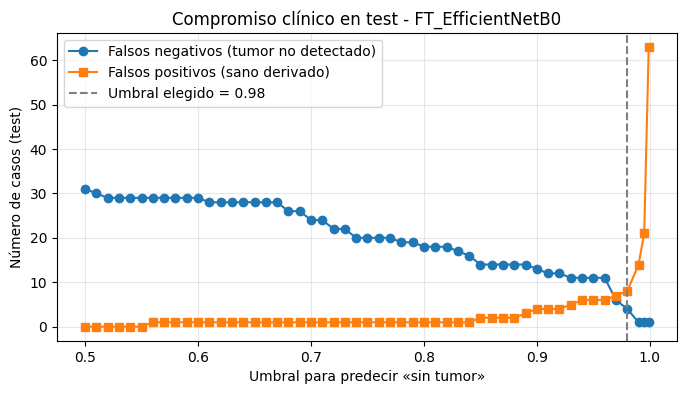

,acc,sens,espec,FN,FP
Estándar (argmax),0.9319,0.9725,1.00,33.0,0.0
Umbral clínico (0.98),0.9312,0.9967,0.98,4.0,8.0


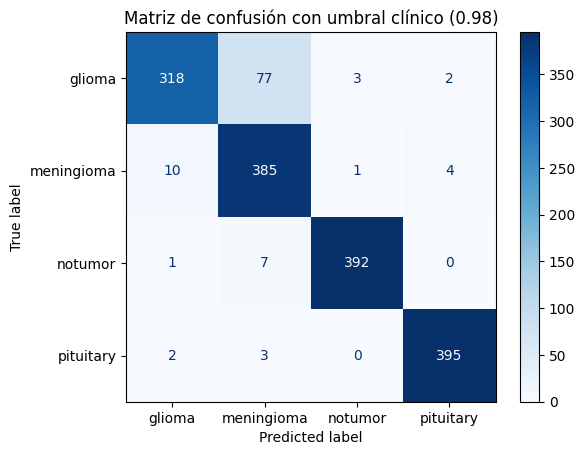

In [21]:
TUMOR_CLS = [i for i in range(4) if i != NO_TUMOR]

def predict_with_threshold(p, t):
    pred = p.argmax(axis=1).copy()
    unsure = (pred == NO_TUMOR) & (p[:, NO_TUMOR] < t)
    pred[unsure] = np.array(TUMOR_CLS)[p[unsure][:, TUMOR_CLS].argmax(axis=1)]
    return pred

def clinical(y, pred):
    tt, tp = y != NO_TUMOR, pred != NO_TUMOR
    return {'acc': (pred == y).mean(),
            'sens': (tt & tp).sum() / tt.sum(),
            'espec': (~tt & ~tp).sum() / (~tt).sum(),
            'FN': int((tt & ~tp).sum()), 'FP': int((~tt & tp).sum())}

# Probabilidades en validación (se recogen batch a batch para mantener el orden)
best_model = tf.keras.models.load_model(f'{SAVE_DIR}/{BEST}.keras')
_, va_best, _ = make_datasets(PRETRAINED['EfficientNetB0'][1])
p_val, y_val = [], []
for x, y in va_best:
    p_val.append(best_model.predict_on_batch(x))
    y_val.append(np.argmax(y, axis=1))
p_val, y_val = np.concatenate(p_val), np.concatenate(y_val)

# Barrido de umbrales
rows = []
for t in list(np.round(np.arange(0.50, 0.99, 0.01), 2)) + [0.99, 0.995, 0.999]:
    v = clinical(y_val, predict_with_threshold(p_val, t))
    s = clinical(y_true, predict_with_threshold(probs[BEST], t))
    rows.append({'umbral': t, 'val_espec': v['espec'],
                 'test_FN': s['FN'], 'test_FP': s['FP'],
                 'test_sens': s['sens'], 'test_espec': s['espec'], 'test_acc': s['acc']})
sweep = pd.DataFrame(rows)

T_CLIN = sweep[sweep.val_espec >= 0.95].umbral.max()
print(f'Umbral elegido en validación: {T_CLIN}')

# Gráfico del compromiso en test
plt.figure(figsize=(8, 4))
plt.plot(sweep.umbral, sweep.test_FN, 'o-', label='Falsos negativos (tumor no detectado)')
plt.plot(sweep.umbral, sweep.test_FP, 's-', label='Falsos positivos (sano derivado)')
plt.axvline(T_CLIN, color='gray', ls='--', label=f'Umbral elegido = {T_CLIN}')
plt.xlabel('Umbral para predecir «sin tumor»'); plt.ylabel('Número de casos (test)')
plt.title(f'Compromiso clínico en test - {BEST}'); plt.legend(); plt.grid(alpha=.3)
plt.show()

# Comparación: decisión estándar frente a umbral clínico
comp = pd.DataFrame({'Estándar (argmax)': clinical(y_true, probs[BEST].argmax(axis=1)),
                     f'Umbral clínico ({T_CLIN})': clinical(y_true, predict_with_threshold(probs[BEST], T_CLIN))}).T
display(comp.round(4))

ConfusionMatrixDisplay(confusion_matrix(y_true, predict_with_threshold(probs[BEST], T_CLIN)),
                       display_labels=CLASSES).plot(cmap='Blues', values_format='d')
plt.title(f'Matriz de confusión con umbral clínico ({T_CLIN})')
plt.show()

**Observaciones 6.2:**
- El umbral elegido en validación (*t* = 0,98) reduce en test los falsos negativos de 33 a 4 (sensibilidad del 97,3 % al 99,7 %), a cambio de 8 falsos positivos (especificidad del 100 % al 98 %). La *accuracy* global prácticamente no cambia (0,932 → 0,931).
- En términos clínicos: de 1.200 pacientes con tumor, el modelo estándar no detectaría a 33 y el modelo con umbral solo a 4; a cambio, 8 de 400 personas sanas serían derivadas a pruebas adicionales.
- El umbral se sitúa en el «codo» de la curva: por encima de 0,98 los falsos positivos crecen rápidamente (63 con *t* = 0,999).
- Aumentan las confusiones glioma → meningioma (56 → 77): son tumores que ahora se detectan como tales, aunque con el subtipo equivocado. Es un error clínicamente menos grave, ya que el paciente es derivado igualmente y el subtipo se confirma por otras pruebas (p. ej., biopsia).

## 6.3 Interpretabilidad con Grad-CAM
Se aplica Grad-CAM sobre la salida del último bloque convolucional de EfficientNetB0 (7 × 7 × 1.280) para visualizar qué regiones de la imagen determinan la predicción. Se analizan aciertos de cada clase y errores representativos, con el fin de comprobar si el modelo basa sus decisiones en la región tumoral.

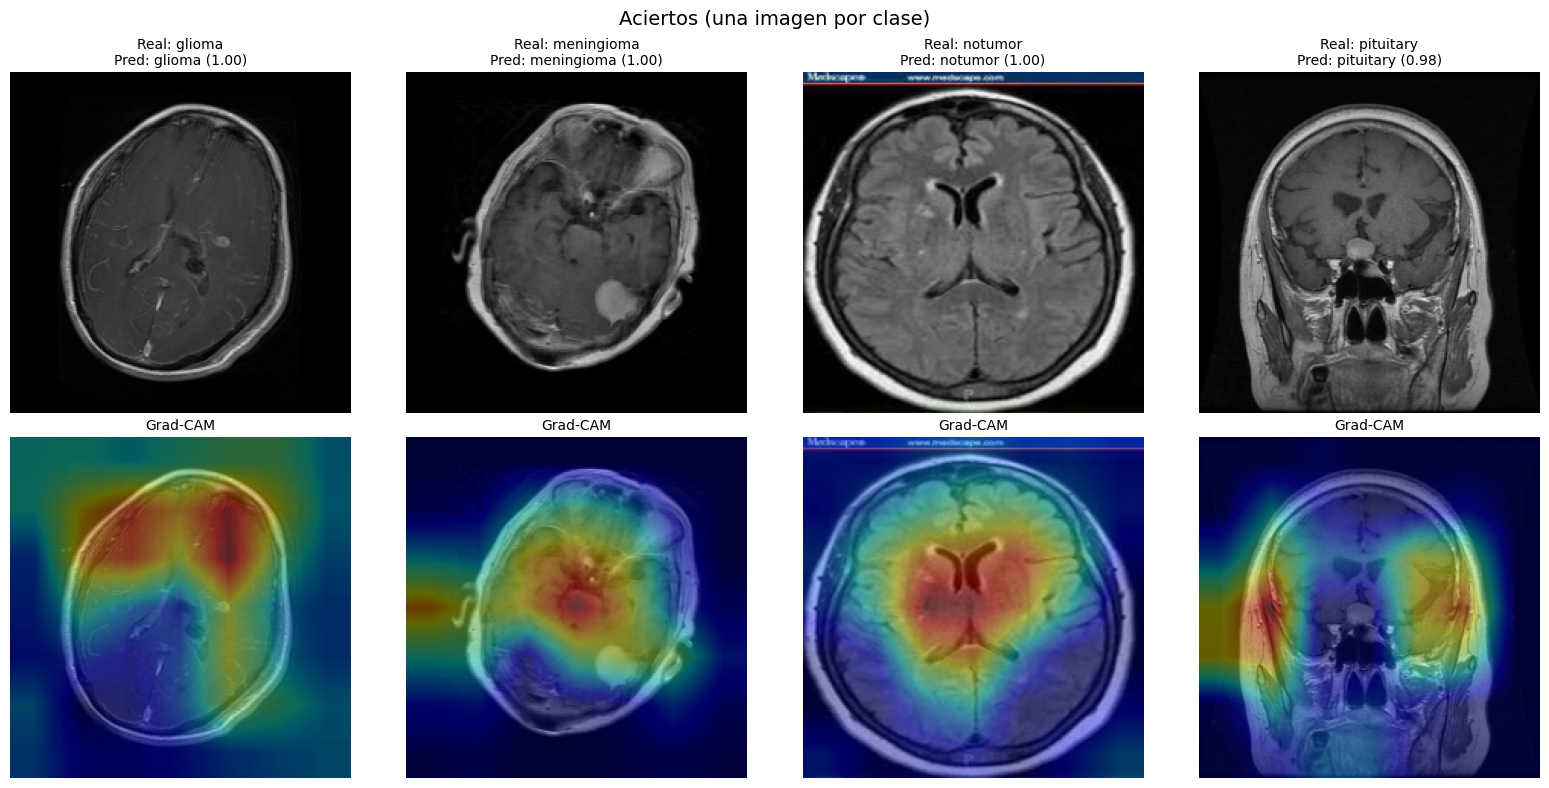

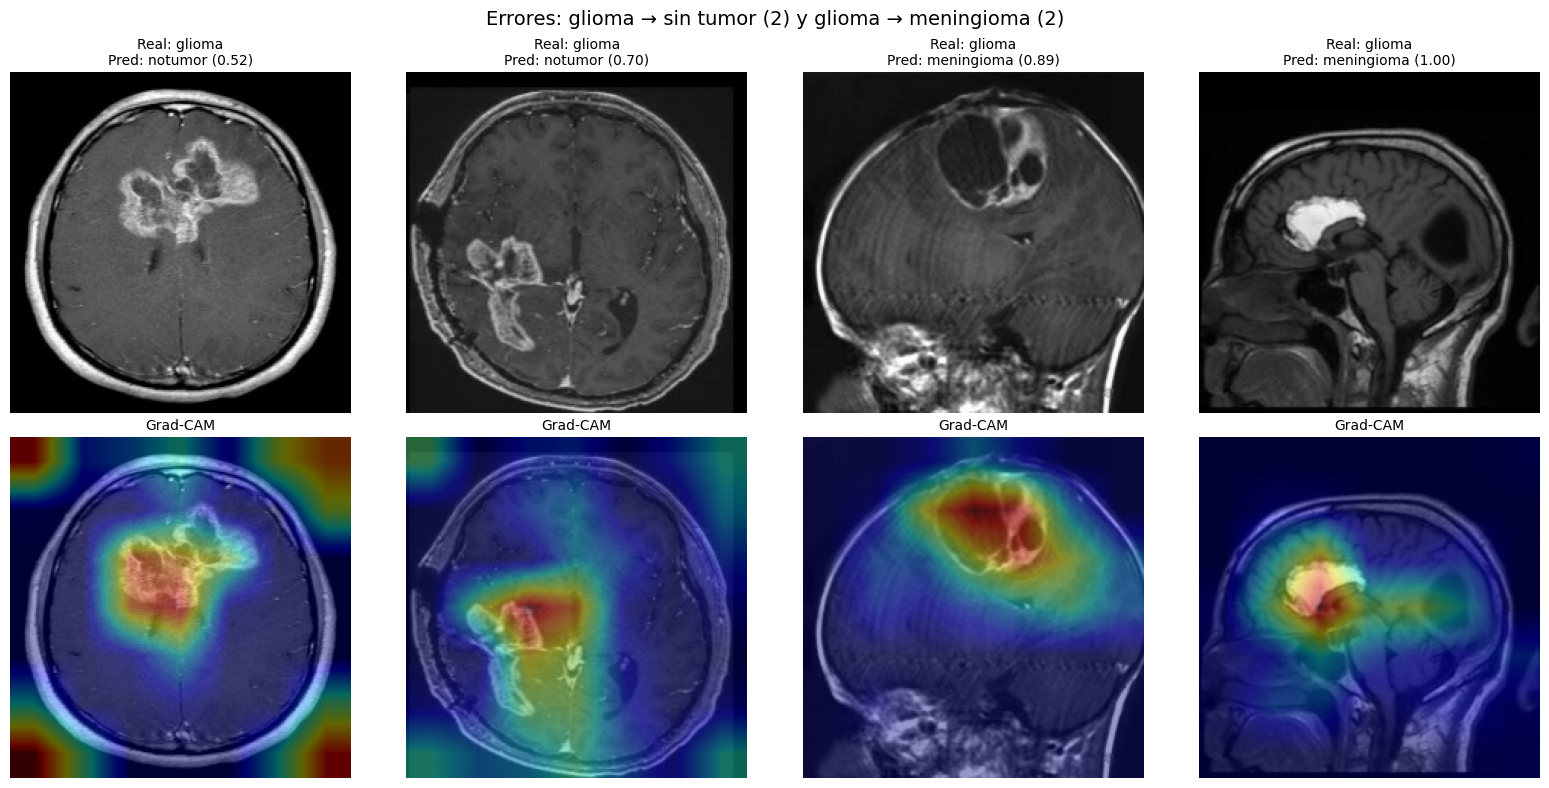

In [22]:
X_test = np.concatenate([x.numpy().astype('uint8') for x, _ in test_ds])
pred_std = probs[BEST].argmax(axis=1)

base = best_model.layers[1]          # EfficientNetB0 (salida = último mapa convolucional)
head = best_model.layers[2:]         # GAP + Dropout + Dense

def grad_cam(img, class_idx):
    x = PRETRAINED['EfficientNetB0'][1](img[None].astype('float32'))
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        h = conv
        for layer in head:
            h = layer(h, training=False)
        score = h[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))                 # importancia de cada canal
    cam = tf.nn.relu(tf.reduce_sum(conv * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]

def show_gradcam(indices, title):
    fig, axes = plt.subplots(2, len(indices), figsize=(4 * len(indices), 8))
    for j, i in enumerate(indices):
        c = pred_std[i]
        cam = grad_cam(X_test[i], c)
        axes[0, j].imshow(X_test[i]); axes[0, j].axis('off')
        axes[0, j].set_title(f'Real: {CLASSES[y_true[i]]}\nPred: {CLASSES[c]} ({probs[BEST][i, c]:.2f})', fontsize=10)
        axes[1, j].imshow(X_test[i]); axes[1, j].imshow(cam, cmap='jet', alpha=0.4)
        axes[1, j].axis('off'); axes[1, j].set_title('Grad-CAM', fontsize=10)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

aciertos = [np.where((y_true == c) & (pred_std == c))[0][0] for c in range(4)]
fn_glioma = list(np.where((y_true == 0) & (pred_std == NO_TUMOR))[0][:2])
glioma_men = list(np.where((y_true == 0) & (pred_std == 1))[0][:2])

show_gradcam(aciertos, 'Aciertos (una imagen por clase)')
show_gradcam(fn_glioma + glioma_men, 'Errores: glioma → sin tumor (2) y glioma → meningioma (2)')

**Observaciones 6.3 (Grad-CAM):**
- En los errores de subtipo (glioma → meningioma) el mapa se concentra sobre la lesión: el modelo localiza el tumor pero lo clasifica mal. Son masas extensas, próximas a la superficie o de bordes bien definidos, rasgos característicos del meningioma, por lo que la confusión es clínicamente comprensible.
- Los dos gliomas clasificados como «sin tumor» tienen confianzas bajas (0,52 y 0,70), lo que explica que el umbral clínico de 0,98 los recupere. En uno de ellos el mapa muestra activación en las esquinas de la imagen (fondo), señal de que el modelo atiende a zonas sin información anatómica.
- En varios aciertos la activación no coincide con la lesión (p. ej., el meningioma situado en la región occipital o la glándula pituitaria), por lo que el modelo podría apoyarse en patrones globales o contextuales y no solo en el tumor.
- Algunas imágenes contienen marcas de agua de sitios web (p. ej., «Medscape»), lo que evidencia que el conjunto procede de fuentes heterogéneas. Esto es coherente con la caída de rendimiento entre validación y test y señala un riesgo de aprendizaje por atajos (*shortcut learning*), a tener en cuenta antes de cualquier uso clínico.

# 7. Conclusiones

1. **Regularización justificada experimentalmente.** El estudio de ablación muestra que sustituir `Flatten` por `GlobalAveragePooling2D` elimina el sobreajuste con 16 veces menos parámetros, y que *Batch Normalization*, *Dropout* y L2 aportan la mayor mejora de la CNN desde cero (0,941 en validación). El *data augmentation*, en cambio, empeoró el rendimiento en todas las configuraciones, probablemente porque las imágenes ya están estandarizadas.

2. **El *fine-tuning* es la técnica decisiva.** Con la base congelada, las redes preentrenadas apenas igualan a la CNN desde cero (0,945 frente a 0,941 en validación); al reajustar el último bloque, EfficientNetB0 alcanza 0,981. Las características de ImageNet necesitan adaptarse al dominio de la resonancia magnética.

3. **Modelo seleccionado: EfficientNetB0 con *fine-tuning*.** Obtiene el mejor resultado en validación con solo 4 M de parámetros y el menor tiempo de entrenamiento. En test alcanza un 93,2 % de *accuracy*, frente al 87,4 % de la CNN desde cero.

4. **Caída de validación a test.** Todos los modelos pierden entre 5 y 7 puntos en test, lo que indica diferencias entre las imágenes de entrenamiento y de test (fuentes heterogéneas). Un modelo así debería validarse con datos de cada centro antes de usarse.

5. **Enfoque clínico: umbral de seguridad.** El modelo estándar no cometía falsos positivos, pero sí 33 falsos negativos. Exigiendo una confianza ≥ 0,98 para diagnosticar «sin tumor» (umbral elegido en validación), los falsos negativos bajan a 4 (sensibilidad del 99,7 %) a cambio de 8 falsos positivos, sin pérdida apreciable de *accuracy*. En cribado, este compromiso es claramente preferible.

6. **Interpretabilidad.** Grad-CAM muestra que en los errores de subtipo el modelo sí localiza la lesión, pero en algunos aciertos se apoya en regiones no tumorales, y el conjunto contiene marcas de agua de origen web. Antes de un uso real serían necesarios datos más homogéneos y validación por especialistas.

**Líneas futuras:** entrenar con datos multicéntricos, incorporar máscaras de segmentación del tumor para guiar la atención del modelo, tratar específicamente la distinción glioma–meningioma y calibrar las probabilidades del modelo.